# Análisis de Ventas Retail · Notebook 02: Análisis exploratorio

## Objetivo
Entender el desempeño de la tienda a partir de los datos limpios del notebook 01: cómo evolucionan las ventas, cuándo se vende más, qué canales y productos sostienen el negocio y qué cambió en los últimos años.

## Preguntas de negocio
- ¿Cómo han evolucionado las ventas desde 2020? ¿Hay crecimiento, caídas o cambios de tendencia?
- ¿En qué meses, días y horas se concentran las ventas?
- ¿Qué peso tiene cada canal de venta y cómo ha cambiado en el tiempo?
- ¿Qué productos generan más venta y cuáles dejan más margen?
- ¿Qué categorías lideran el negocio en los últimos años?
- ¿Cómo ha evolucionado el ticket promedio?

## Datos
- `ventas_limpias.parquet`: 194.991 líneas de venta, sin glosas, con `categoria` unificada y `canal_venta` construido desde la forma de pago (ver notebook 01).
- Los montos están anonimizados: se analizan tendencias y proporciones, no cifras absolutas.
- Se usa la **venta neta** (sin IVA) como medida principal, para que sea comparable con el costo y el margen.
- 2026 es un año incompleto (hasta el 8 de noviembre), lo que se considera al comparar años.

## Etapas
1. Carga y verificación de los datos limpios
2. Evolución de las ventas en el tiempo
3. Estacionalidad: mes, día de la semana y hora
4. Canales de venta
5. Productos: ranking por venta y por margen
6. Categorías (2024–2026)
7. Ticket promedio
8. Conclusiones

## 1. Carga y verificación de los datos limpios

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.0f}'.format)
sns.set_theme(style='whitegrid')


df = pd.read_parquet('../data/processed/ventas_limpias.parquet')

print(df.shape)
print(df['fecha'].min(), '→', df['fecha'].max())
df[['fecha', 'sku', 'categoria', 'canal_venta']].dtypes

(194991, 30)
2020-02-29 00:00:00 → 2026-11-08 00:00:00


fecha          datetime64[us]
sku                       str
categoria                 str
canal_venta               str
dtype: object

**Interpretación:** Los datos limpios se cargaron correctamente: 194.991 líneas entre el 29 de febrero de 2020 y el 8 de noviembre de 2026, con los tipos de datos preservados por el formato Parquet.

## 2. Evolución de las ventas en el tiempo

### 2.1 Venta neta por año

In [2]:
anual = df.groupby(df['fecha'].dt.year).agg(
    venta_neta=('venta_total_neta', 'sum'),
    documentos=('id_documento', 'nunique'),
)
anual['variacion_pct'] = anual['venta_neta'].pct_change() * 100
anual

,venta_neta,documentos,variacion_pct
fecha,,,
2020,"263,311,465",8260,NaN
2021,"355,490,892",10449,35
2022,"379,540,294",10399,7
2023,"453,145,691",11334,19
2024,"451,314,951",11135,-0
2025,"499,379,534",12326,11
2026,"370,282,718",9672,-26


**Interpretación:** la venta neta crece cada año entre 2020 y 2023, se mantiene plana en 2024 y vuelve a crecer en 2025. Dos precauciones al leer esta tabla:
- **2020 está incompleto** (parte el 29 de febrero), por lo que el crecimiento de 2021 aparece sobreestimado.
- **2026 también está incompleto** (hasta el 8 de noviembre): su −26% no es comparable. La comparación justa del mismo período está en la sección 2.3.

### 2.2 Venta neta mensual

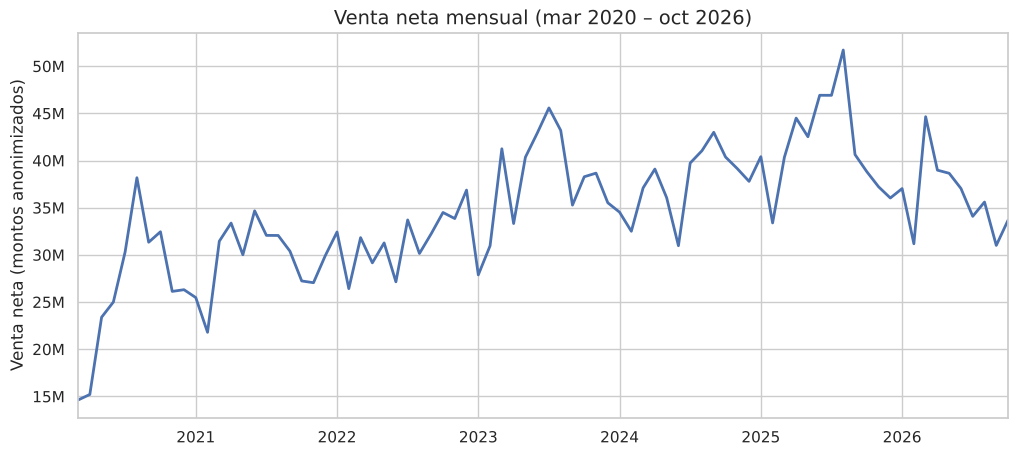

In [3]:
mensual = df.set_index('fecha').resample('MS')['venta_total_neta'].sum()
mensual = mensual.loc['2020-03':'2026-10']  # se excluyen meses incompletos

fig, ax = plt.subplots(figsize=(12, 5))
mensual.plot(ax=ax, linewidth=2)
ax.set_title('Venta neta mensual (mar 2020 – oct 2026)', fontsize=14)
ax.set_xlabel('')
ax.set_ylabel('Venta neta (montos anonimizados)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))
plt.show()

**Interpretación:** - **2020:** parte muy bajo en marzo y abril (inicio de la pandemia) y sube rápido hasta un peak a mitad de año.
- **2021–2025:** tendencia de crecimiento con un patrón que se repite cada año: caídas a comienzos de año y peaks a mitad de año (se mide en la sección 3).
- **El peak más alto** ocurre a mediados de 2025; desde ahí la curva baja y no se recupera en 2026.

**Hipótesis (contexto del negocio):** la inversión en anuncios de Meta se redujo desde septiembre de 2025, hasta llegar a niveles mínimos en agosto de 2026. Esto coincide con el inicio de la caída de ventas. Se pondrá a prueba en el análisis de canales (sección 4).

### 2.3 Comparación del mismo período (1 de enero al 8 de noviembre)

In [4]:
mismo_periodo = df[(df['fecha'].dt.month < 11) |
                   ((df['fecha'].dt.month == 11) & (df['fecha'].dt.day <= 8))]

ytd = mismo_periodo.groupby(mismo_periodo['fecha'].dt.year).agg(
    venta_neta=('venta_total_neta', 'sum'),
    documentos=('id_documento', 'nunique'),
)
ytd['variacion_pct'] = ytd['venta_neta'].pct_change() * 100
ytd

,venta_neta,documentos,variacion_pct
fecha,,,
2020,"218,152,492",6845,NaN
2021,"307,212,568",9078,41
2022,"318,637,143",8790,4
2023,"389,625,842",9772,22
2024,"384,717,927",9482,-1
2025,"436,069,451",10786,13
2026,"370,282,718",9672,-15


**Interpretación:** Comparando el mismo período (1 de enero al 8 de noviembre), 2026 muestra una caída real de 15% respecto a 2025. Se explica por una baja de cerca de 10% en la cantidad de ventas y de 5% en el ticket promedio. El crecimiento de 2021 está sobreestimado porque 2020 no incluye enero ni febrero.

## 3. Estacionalidad: mes, día de la semana y hora

### 3.1 ¿En qué meses se vende más?

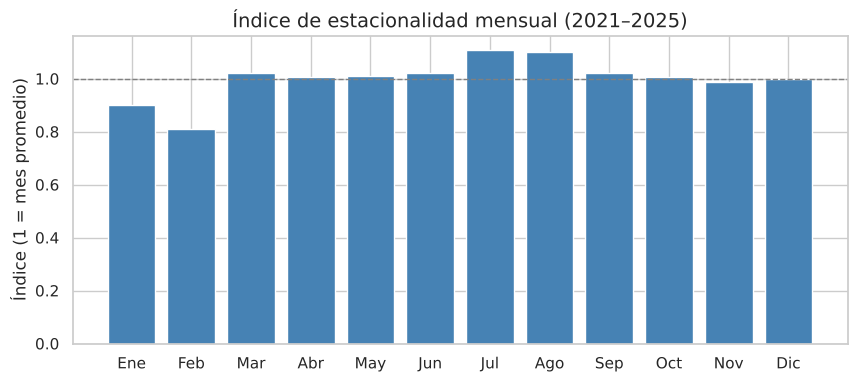

mes
1     0.90
2     0.81
3     1.02
4     1.01
5     1.01
6     1.02
7     1.11
8     1.10
9     1.02
10    1.01
11    0.99
12    1.00
Name: indice, dtype: str

In [5]:
m = mensual.loc['2021-01':'2025-12'].to_frame('venta')
m['anio'] = m.index.year
m['mes'] = m.index.month

# índice: venta del mes / promedio mensual de ese mismo año
m['indice'] = m['venta'] / m.groupby('anio')['venta'].transform('mean')
estacionalidad = m.groupby('mes')['indice'].mean()

meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(meses, estacionalidad.values, color='steelblue')
ax.axhline(1, color='gray', linestyle='--', linewidth=1)
ax.set_title('Índice de estacionalidad mensual (2021–2025)', fontsize=14)
ax.set_ylabel('Índice (1 = mes promedio)')
plt.show()

estacionalidad.map('{:.2f}'.format)

**Interpretación:** **febrero (0,81) y enero (0,90)** son los meses más bajos: coinciden con las vacaciones de verano, cuando mucha gente sale de Santiago. **Julio (1,11) y agosto (1,10)** son los más altos: pleno invierno, temporada de resfríos, cuando suben vitaminas, suplementos para las defensas y productos como el aceite de orégano o los shots de jengibre. El resto del año es parejo, cerca del promedio.

Implicancia: reforzar el stock de productos de invierno antes de julio y usar enero y febrero para promociones que activen la demanda.

### 3.2 ¿Qué días se vende más?

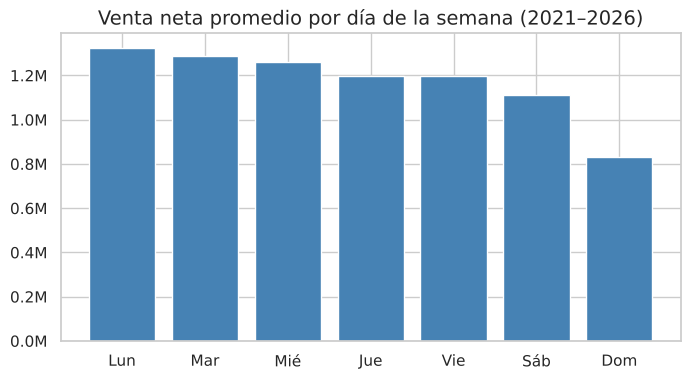

In [6]:
diaria = df.set_index('fecha').resample('D')['venta_total_neta'].sum()
diaria = diaria.loc['2021-01-01':'2026-10-31']

por_dia = diaria.groupby(diaria.index.dayofweek).mean()
dias = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dias, por_dia.values, color='steelblue')
ax.set_title('Venta neta promedio por día de la semana (2021–2026)', fontsize=14)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
plt.show()

**Interpretación:** el **lunes es el día de mayor venta** y la venta baja gradualmente durante la semana; el **domingo es el más bajo**, cerca de 35% menos que el lunes. Que el lunes sea el día más fuerte es poco común en retail; una posible explicación es que parte de los pedidos online del fin de semana se procesan y boletean el lunes (hipótesis pendiente de validar por canal).

### 3.3 ¿A qué hora llegan más clientes a la tienda física?

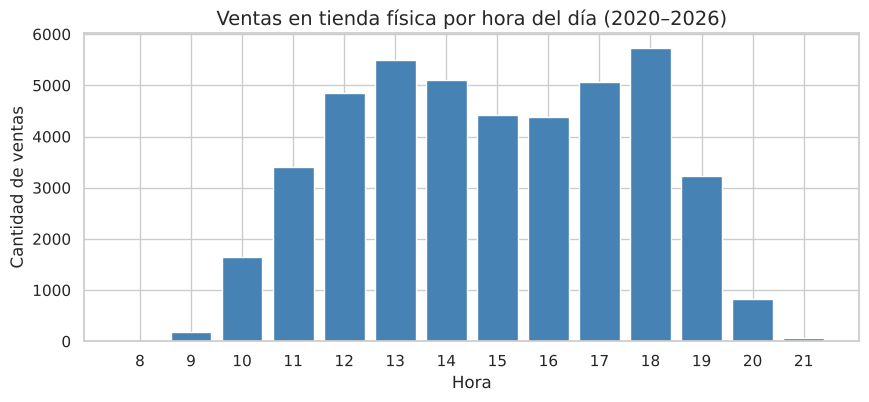

In [7]:
df['hora_num'] = pd.to_datetime(df['hora'], format='%H:%M:%S').dt.hour

fisica = df[df['canal_venta'] == 'Tienda física']
por_hora = fisica.groupby('hora_num')['id_documento'].nunique()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(por_hora.index, por_hora.values, color='steelblue')
ax.set_title('Ventas en tienda física por hora del día (2020–2026)', fontsize=14)
ax.set_xlabel('Hora')
ax.set_ylabel('Cantidad de ventas')
ax.set_xticks(por_hora.index)
plt.show()

**Interpretación:** la tienda física tiene **dos peaks de clientes al día**: las **13:00** (hora de almuerzo) y las **18:00** (salida del trabajo, el peak más alto). Entre ambos, las 15 y 16 hrs son un valle; la mañana parte lento y después de las 19 la actividad cae rápido.

Implicancia operativa: reforzar la dotación en caja a las 13 y 18 hrs, programar colaciones en el valle de 15 a 16 hrs y usar la mañana para reponer stock.

## 4. Canales de venta

### 4.1 ¿Cómo ha cambiado el peso de cada canal?

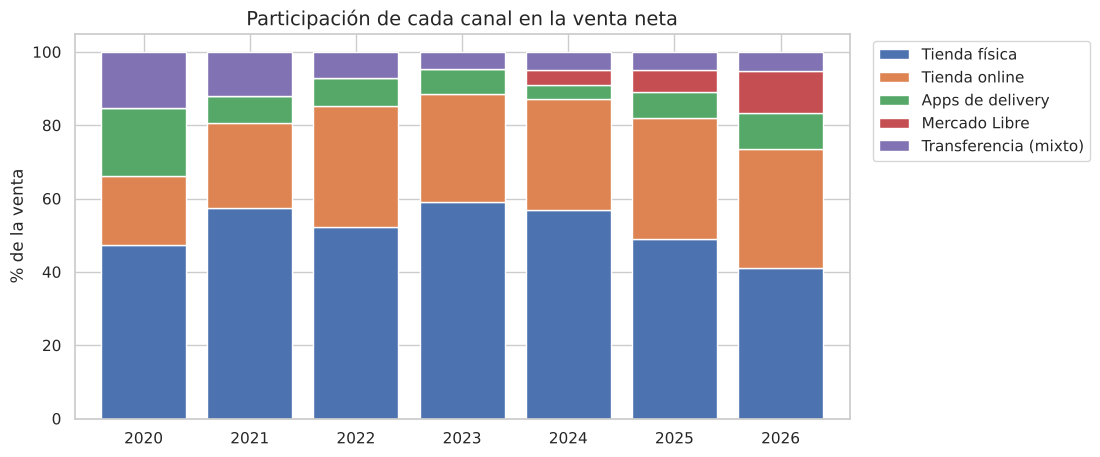

canal_venta,Tienda física,Tienda online,Apps de delivery,Mercado Libre,Transferencia (mixto)
fecha,,,,,
2020,47.3%,18.7%,18.5%,0.0%,15.4%
2021,57.4%,23.2%,7.3%,0.0%,12.1%
2022,52.3%,33.0%,7.4%,0.0%,7.2%
2023,59.0%,29.6%,6.7%,0.0%,4.7%
2024,56.8%,30.4%,3.9%,3.9%,5.1%
2025,49.0%,32.8%,7.2%,5.9%,5.1%
2026,41.2%,32.4%,9.8%,11.4%,5.2%


In [8]:
canales = ['Tienda física', 'Tienda online', 'Apps de delivery', 'Mercado Libre', 'Transferencia (mixto)']
vc = df[df['canal_venta'].isin(canales)]

por_canal = vc.pivot_table(index=vc['fecha'].dt.year, columns='canal_venta',
                           values='venta_total_neta', aggfunc='sum')[canales].fillna(0)
participacion = por_canal.div(por_canal.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
participacion.plot(kind='bar', stacked=True, ax=ax, width=0.8)
ax.set_title('Participación de cada canal en la venta neta', fontsize=14)
ax.set_xlabel('')
ax.set_ylabel('% de la venta')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.show()

participacion.map('{:.1f}%'.format)

**Interpretación:** - **Tienda física:** llegó a su punto más alto en 2023 (59% de la venta) y desde ahí cae año a año, hasta el 41% en 2026.
- **Tienda online:** creció entre 2020 y 2022 y se mantiene estable, cerca de un tercio de la venta.
- **Apps de delivery:** muy relevantes en 2020 (18,5%, pandemia), bajan hasta 3,9% en 2024 y se recuperan en 2026 (9,8%).
- **Mercado Libre:** parte en 2023 y en 2026 ya representa el 11,4%; es el canal que más crece.
- **Transferencias:** pesaban mucho en 2020–2021 (probablemente pedidos por WhatsApp durante la pandemia) y hoy se estabilizan cerca del 5%.

### 4.2 Variación por canal: 2026 vs 2025 (mismo período)

In [9]:
mp = mismo_periodo[mismo_periodo['fecha'].dt.year.isin([2025, 2026]) &
                   mismo_periodo['canal_venta'].isin(canales)]

comparacion = mp.groupby([mp['canal_venta'], mp['fecha'].dt.year])['venta_total_neta'].sum().unstack()
comparacion['variacion_pct'] = (comparacion[2026] / comparacion[2025] - 1) * 100
comparacion.sort_values('variacion_pct')

fecha,2025,2026,variacion_pct
canal_venta,,,
Tienda física,"218,219,745","152,753,145",-30
Tienda online,"142,164,985","120,147,949",-15
Transferencia (mixto),"21,939,006","19,356,414",-12
Apps de delivery,"29,532,237","36,495,574",24
Mercado Libre,"25,338,465","42,444,179",68


**Interpretación:** la caída de 2026 se concentra en la tienda física (-30%), seguida por la tienda online (-15%). En cambio, las apps de delivery (+24%) y Mercado Libre (+68%) crecen. Esto coincide con lo observado en la operación diaria: hay notoriamente menos clientes presenciales. Hipótesis: la reducción de anuncios en Meta habría afectado la llegada de clientes a la tienda, y parte de ellos estaría migrando a canales de terceros.


### 4.3 Tienda física: cantidad de ventas y ticket promedio

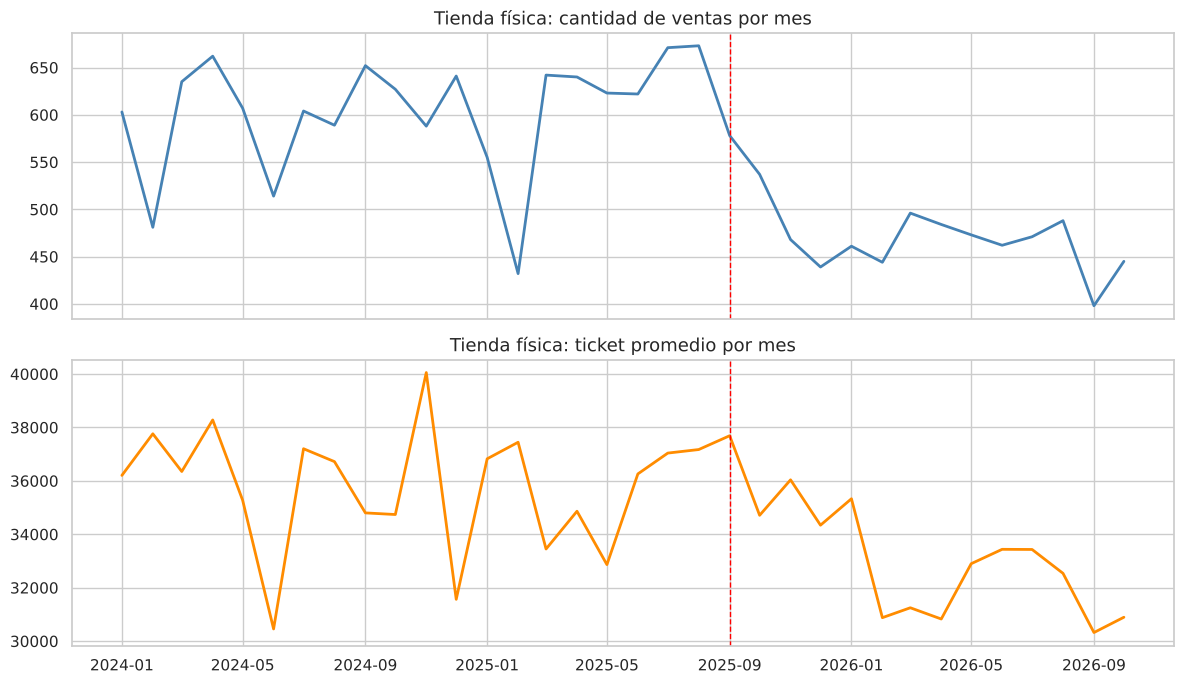

In [10]:
fis = df[df['canal_venta'] == 'Tienda física']

m_fis = fis.set_index('fecha').resample('MS').agg({'id_documento': 'nunique', 'venta_total_neta': 'sum'})
m_fis = m_fis.loc['2024-01':'2026-10']
m_fis['ticket'] = m_fis['venta_total_neta'] / m_fis['id_documento']

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(m_fis.index, m_fis['id_documento'], linewidth=2, color='steelblue')
axes[0].set_title('Tienda física: cantidad de ventas por mes', fontsize=13)

axes[1].plot(m_fis.index, m_fis['ticket'], linewidth=2, color='darkorange')
axes[1].set_title('Tienda física: ticket promedio por mes', fontsize=13)

for ax in axes:
    ax.axvline(pd.Timestamp('2025-09-01'), color='red', linestyle='--', linewidth=1)

plt.tight_layout()
plt.show()

**Interpretación:** La cantidad de ventas en tienda física cae cerca de un 25-30% desde septiembre de 2025 y no se recupera, coincidiendo con el inicio de la reducción de anuncios en Meta. El ticket promedio también baja, aunque menos. Esto confirma lo observado en la operación: la caída se explica principalmente por menos clientes, no por compras más pequeñas. La coincidencia temporal refuerza la hipótesis, aunque no prueba causalidad; para confirmarla se necesitarían los datos de inversión en anuncios.

### 4.4 Evolución mensual de la venta por canal

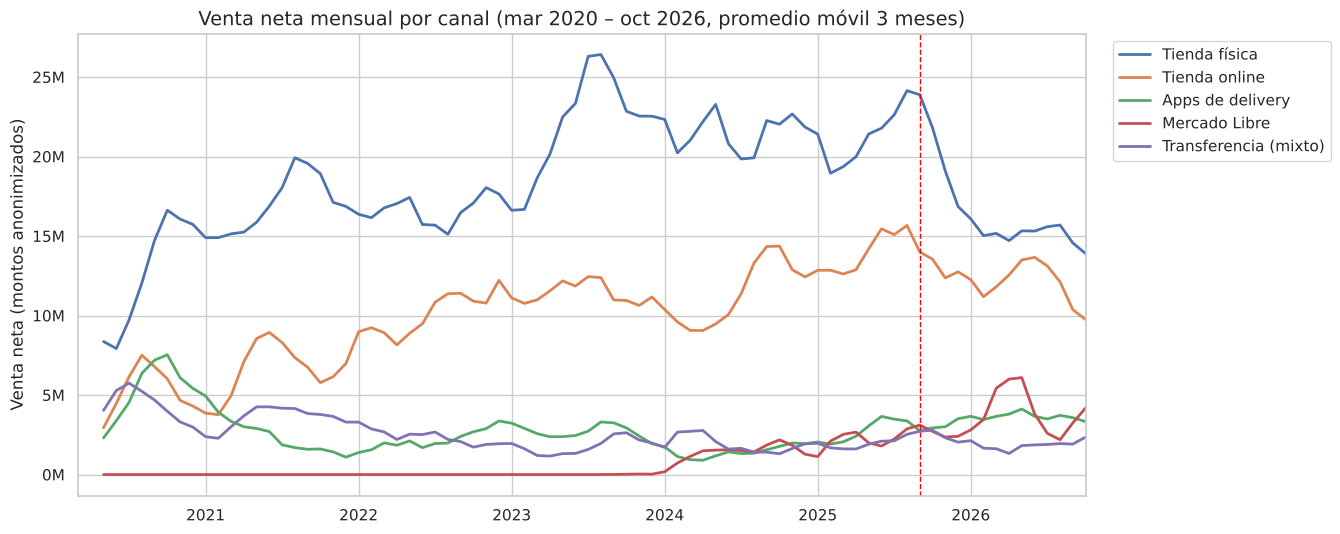

In [11]:
mensual_canal = vc.pivot_table(index=pd.Grouper(key='fecha', freq='MS'),
                               columns='canal_venta',
                               values='venta_total_neta',
                               aggfunc='sum')[canales].fillna(0)
mensual_canal = mensual_canal.loc['2020-03':'2026-10']
fig, ax = plt.subplots(figsize=(13, 6))
mensual_canal.rolling(3).mean().plot(ax=ax, linewidth=2)  # promedio móvil de 3 meses
ax.axvline(pd.Timestamp('2025-09-01'), color='red', linestyle='--', linewidth=1)
ax.set_title('Venta neta mensual por canal (mar 2020 – oct 2026, promedio móvil 3 meses)', fontsize=14)
ax.set_xlabel('')
ax.set_ylabel('Venta neta (montos anonimizados)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

**Interpretación:** el gráfico (suavizado con un promedio móvil de 3 meses para ver mejor la tendencia) muestra que la tienda física cae con fuerza desde la línea de septiembre de 2025, mientras Mercado Libre y las apps de delivery crecen en el mismo período. La tienda online baja de forma más moderada. Los canales se mueven en direcciones opuestas, consistente con la hipótesis de que parte de los clientes migró de la tienda a canales de terceros.

## 5. Productos: ranking por venta y por margen

### 5.1 ¿Qué productos generan más venta? (últimos 12 meses)

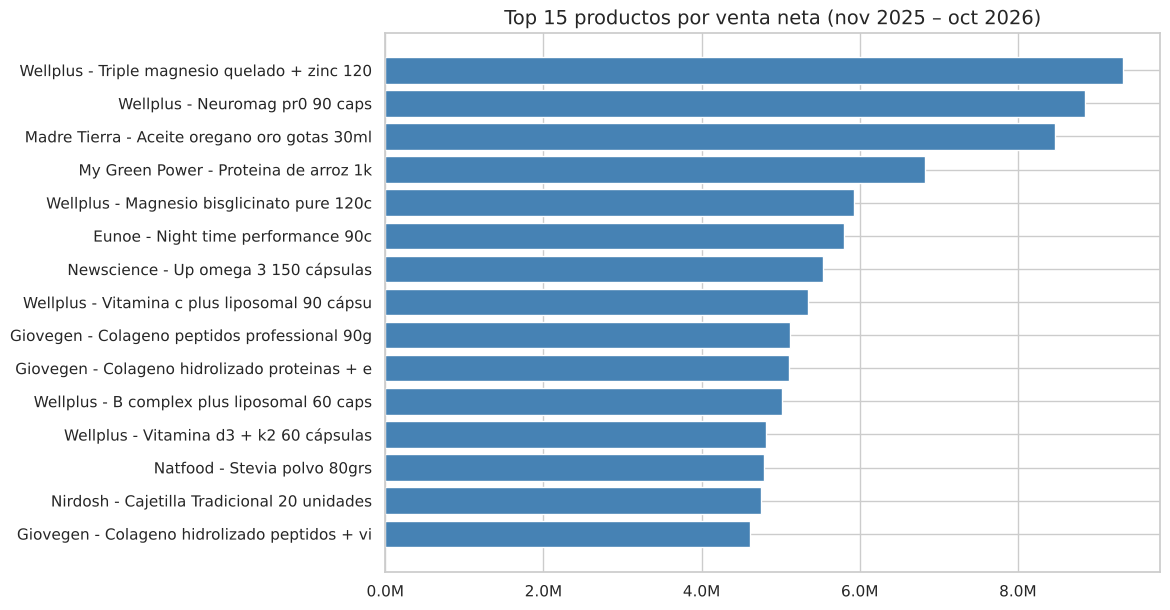

In [12]:
ult12 = df[(df['fecha'] >= '2025-11-01') & (df['fecha'] <= '2026-10-31')]
ult12 = ult12[~ult12['producto_servicio'].str.contains('Despacho|Bolsa', case=False)]

productos = ult12.groupby('producto_servicio').agg(
    unidades=('cantidad', 'sum'),
    venta_neta=('venta_total_neta', 'sum'),
)
top_venta = productos.nlargest(15, 'venta_neta')

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_venta.index.str[:45][::-1], top_venta['venta_neta'][::-1], color='steelblue')
ax.set_title('Top 15 productos por venta neta (nov 2025 – oct 2026)', fontsize=14)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
plt.show()

**Interpretación:** los suplementos dominan el ranking de venta: magnesio, aceite de orégano, proteína, omega 3, vitaminas y colágeno. Se excluyen los cobros de despacho y las bolsas, que no son productos ("Despacho región metropolitana" aparecía en el puesto 8). Algunos productos pueden aparecer con nombres distintos, lo que es una limitación menor del ranking.

### 5.2 ¿Qué productos dejan más margen? (últimos 12 meses)

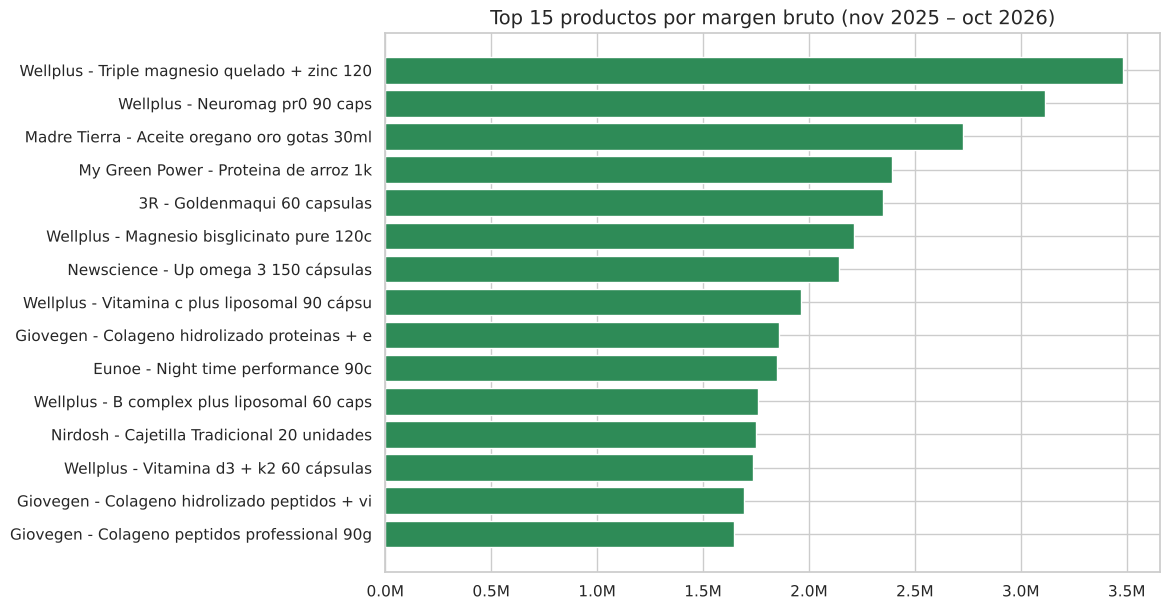

,unidades,venta_neta,margen,pct_margen
producto_servicio,,,,
Wellplus - Triple magnesio quelado + zinc 120 cápsulas,326,"9,562,417","3,484,165",36
Wellplus - Neuromag pr0 90 caps,166,"8,844,715","3,115,455",35
Madre Tierra - Aceite oregano oro gotas 30ml,209,"8,469,749","2,725,615",32
My Green Power - Proteina de arroz 1k,232,"6,819,343","2,393,693",35
3R - Goldenmaqui 60 capsulas,175,"3,553,225","2,347,184",66
Wellplus - Magnesio bisglicinato pure 120c,245,"5,932,095","2,213,443",37
Newscience - Up omega 3 150 cápsulas,130,"5,580,461","2,140,413",38
Wellplus - Vitamina c plus liposomal 90 cápsulas,175,"5,346,002","1,964,715",37
Giovegen - Colageno hidrolizado proteinas + extractos + aminoacidos + probioticos + vitaminas 43,82,"5,248,375","1,860,153",35


In [13]:
con_costo = ult12[ult12['costo_total_neto'] > 0]

margen_prod = con_costo.groupby('producto_servicio').agg(
    unidades=('cantidad', 'sum'),
    venta_neta=('venta_total_neta', 'sum'),
    margen=('margen', 'sum'),
)
margen_prod['pct_margen'] = margen_prod['margen'] / margen_prod['venta_neta'] * 100
top_margen = margen_prod.nlargest(15, 'margen')

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_margen.index.str[:45][::-1], top_margen['margen'][::-1], color='seagreen')
ax.set_title('Top 15 productos por margen bruto (nov 2025 – oct 2026)', fontsize=14)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
plt.show()

top_margen

**Interpretación:** - **Los suplementos dominan también en margen**, con **Wellplus** como marca clave: 6 de los 15 productos con más margen. Es una fortaleza, pero también una dependencia de un solo proveedor.
- **3R Goldenmaqui** no está entre los 15 que más venden, pero es quinto en margen por su **66%**, muy por sobre el resto (32–38%). Conviene impulsarlo y validar que su costo esté bien registrado.
- **Natfood Stevia** aparece en el ranking de venta pero no en el de margen: vende mucho, pero deja poco.
- Los márgenes del resto son muy parejos, lo que sugiere una política de precios consistente.

### 5.3 ¿Cuántos productos concentran la venta? (Pareto)

Productos con venta: 1,526
El 80% de la venta lo generan 368 productos (24.1% del catálogo)


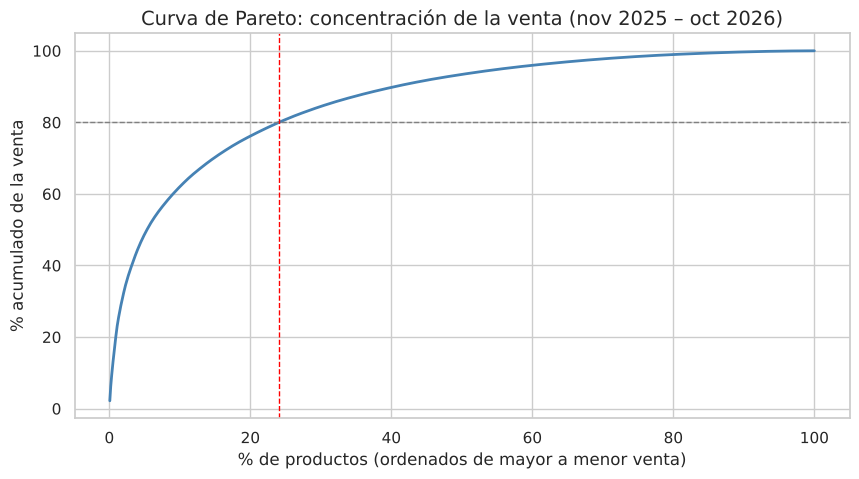

In [14]:
ventas_prod = ult12.groupby('producto_servicio')['venta_total_neta'].sum().sort_values(ascending=False)
ventas_prod = ventas_prod[ventas_prod > 0]

acumulado = ventas_prod.cumsum() / ventas_prod.sum() * 100
n_80 = (acumulado <= 80).sum() + 1
pct_80 = n_80 / len(ventas_prod) * 100

print(f'Productos con venta: {len(ventas_prod):,}')
print(f'El 80% de la venta lo generan {n_80:,} productos ({pct_80:.1f}% del catálogo)')

x = np.arange(1, len(ventas_prod) + 1) / len(ventas_prod) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, acumulado.values, linewidth=2, color='steelblue')
ax.axhline(80, color='gray', linestyle='--', linewidth=1)
ax.axvline(pct_80, color='red', linestyle='--', linewidth=1)
ax.set_title('Curva de Pareto: concentración de la venta (nov 2025 – oct 2026)', fontsize=14)
ax.set_xlabel('% de productos (ordenados de mayor a menor venta)')
ax.set_ylabel('% acumulado de la venta')
plt.show()

**Interpretación:** el **24% de los productos (368 de 1.526) genera el 80% de la venta**, muy cerca de la regla 80/20. En el otro extremo, la mitad del catálogo aporta menos del 7% de la venta.

Implicancias: los 368 productos del grupo principal nunca deberían tener quiebre de stock, y la cola larga merece revisión por el espacio y el capital inmovilizado que representa (considerando que en una tienda de productos naturales la variedad también atrae clientes). Esta división es la base de una clasificación ABC de inventario.

## 6. Categorías (2024–2026)
Por la reestructuración del catálogo en 2026, el análisis por categoría se limita al período con cobertura superior al 85% de la venta (ver notebook 01, sección 2.4).

### 6.1 ¿Qué categorías lideran la venta?

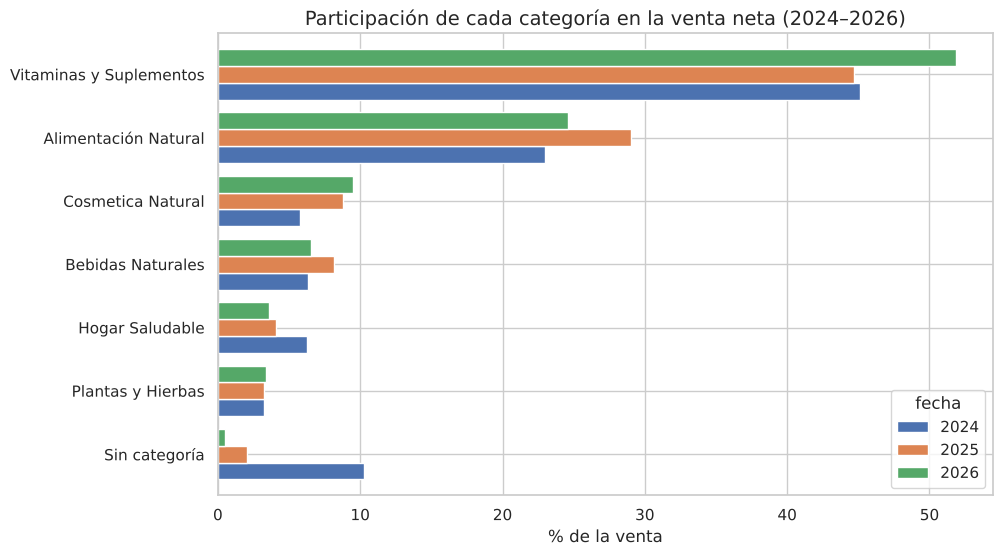

fecha,2024,2025,2026
categoria,,,
Sin categoría,10.3%,2.0%,0.5%
Plantas y Hierbas,3.2%,3.2%,3.4%
Hogar Saludable,6.3%,4.1%,3.6%
Bebidas Naturales,6.3%,8.1%,6.6%
Cosmetica Natural,5.8%,8.8%,9.5%
Alimentación Natural,23.0%,29.0%,24.6%
Vitaminas y Suplementos,45.1%,44.7%,51.9%


In [15]:
no_producto = df['producto_servicio'].str.contains('Despacho|Bolsa', case=False)
cat = df[(df['fecha'].dt.year >= 2024) & ~no_producto]

por_cat = cat.pivot_table(index='categoria', columns=cat['fecha'].dt.year,
                          values='venta_total_neta', aggfunc='sum')
part_cat = por_cat.div(por_cat.sum(axis=0), axis=1) * 100
part_cat = part_cat.sort_values(2026)

fig, ax = plt.subplots(figsize=(10, 6))
part_cat.plot(kind='barh', ax=ax, width=0.8)
ax.set_title('Participación de cada categoría en la venta neta (2024–2026)', fontsize=14)
ax.set_xlabel('% de la venta')
ax.set_ylabel('')
plt.show()

part_cat.map('{:.1f}%'.format)

**Interpretación:** **Vitaminas y Suplementos es la mitad del negocio** y sube de 44,7% a 51,9% en 2026. **Alimentación Natural** es la segunda categoría, pero baja de 29,0% a 24,6%. **Cosmética Natural** crece de forma sostenida (de 5,8% a 9,5%). "Sin categoría" baja a 0,5%, lo que confirma que la cobertura de categorías en 2026 es casi total.

### 6.2 Variación por categoría: 2026 vs 2025 (mismo período)

In [16]:
mp_cat = mismo_periodo[mismo_periodo['fecha'].dt.year.isin([2025, 2026]) &
                       ~mismo_periodo['producto_servicio'].str.contains('Despacho|Bolsa', case=False)]

comp_cat = mp_cat.groupby([mp_cat['categoria'], mp_cat['fecha'].dt.year])['venta_total_neta'].sum().unstack()
comp_cat['variacion_pct'] = (comp_cat[2026] / comp_cat[2025] - 1) * 100
comp_cat.sort_values('variacion_pct')

fecha,2025,2026,variacion_pct
categoria,,,
Sin categoría,"8,574,056","1,766,283",-79
Bebidas Naturales,"34,047,719","23,818,125",-30
Alimentación Natural,"124,247,853","89,290,637",-28
Hogar Saludable,"17,511,568","13,025,872",-26
Plantas y Hierbas,"14,582,727","12,313,647",-16
Cosmetica Natural,"36,731,591","34,293,535",-7
Vitaminas y Suplementos,"189,361,036","187,999,148",-1


**Interpretación:** Vitaminas y Suplementos representa la mitad de la venta y se mantuvo estable en 2026 (−1%), mientras Alimentación, Bebidas y Hogar caen entre 26% y 30%. Esto es consistente con la caída de clientes en tienda física: los suplementos son compras planificadas que se sostienen en todos los canales, mientras las compras cotidianas y de impulso dependen del flujo de clientes al local. La variación de “Sin categoría” refleja productos descontinuados y no se interpreta.

## 7. Ticket promedio

### 7.1 y 7.2 Ticket promedio por año y por canal

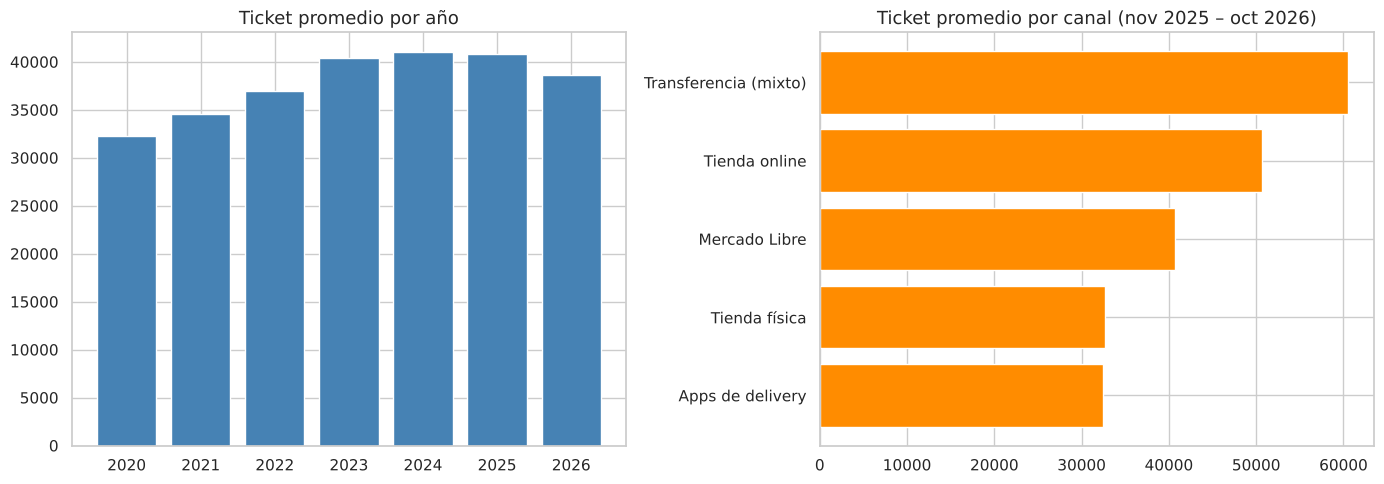

,venta_neta,documentos,ticket
fecha,,,
2020,"264,719,166",8201,"32,279"
2021,"358,403,150",10371,"34,558"
2022,"382,562,107",10339,"37,002"
2023,"455,569,192",11290,"40,352"
2024,"454,463,145",11079,"41,020"
2025,"501,241,984",12283,"40,808"
2026,"371,845,562",9638,"38,581"


In [17]:
ventas = df[df['tipo_movimiento'] == 'venta']

# 7.1 Ticket promedio por año
anual_t = ventas.groupby(ventas['fecha'].dt.year).agg(
    venta_neta=('venta_total_neta', 'sum'),
    documentos=('id_documento', 'nunique'),
)
anual_t['ticket'] = anual_t['venta_neta'] / anual_t['documentos']

# 7.2 Ticket promedio por canal (últimos 12 meses)
v12 = ventas[(ventas['fecha'] >= '2025-11-01') & (ventas['fecha'] <= '2026-10-31') &
             ventas['canal_venta'].isin(canales)]
canal_t = v12.groupby('canal_venta').agg(
    venta_neta=('venta_total_neta', 'sum'),
    documentos=('id_documento', 'nunique'),
)
canal_t['ticket'] = canal_t['venta_neta'] / canal_t['documentos']
canal_t = canal_t.sort_values('ticket')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(anual_t.index.astype(str), anual_t['ticket'], color='steelblue')
axes[0].set_title('Ticket promedio por año', fontsize=13)

axes[1].barh(canal_t.index, canal_t['ticket'], color='darkorange')
axes[1].set_title('Ticket promedio por canal (nov 2025 – oct 2026)', fontsize=13)

plt.tight_layout()
plt.show()

anual_t


**Interpretación:** - **Por año:** el ticket sube de unos 32.000 en 2020 a 41.000 en 2024, se mantiene en 2025 y baja a 38.600 en 2026 (−5%). Estos montos **no están ajustados por inflación**: en Chile, 2021 y 2022 tuvieron inflación muy alta, por lo que parte del crecimiento es alza de precios. Eso hace más relevante la caída de 2026.
- **Por canal:** las transferencias tienen el ticket más alto (pedidos grandes o empresas), seguidas de la tienda online (pedidos más grandes para justificar el despacho) y Mercado Libre. La tienda física y las apps de delivery tienen tickets similares, de compras más chicas y frecuentes.

### 7.3 Ticket promedio por año y canal

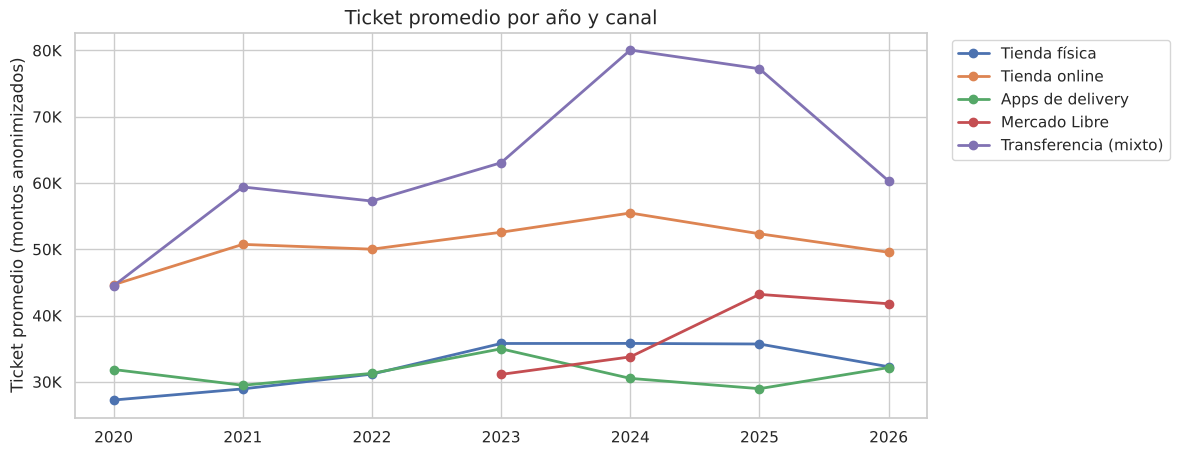

canal_venta,Tienda física,Tienda online,Apps de delivery,Mercado Libre,Transferencia (mixto)
fecha,,,,,
2020,"27,253","44,655","31,858",NaN,"44,488"
2021,"28,933","50,738","29,480",NaN,"59,402"
2022,"31,163","50,013","31,277",NaN,"57,272"
2023,"35,783","52,568","34,980","31,121","63,060"
2024,"35,796","55,470","30,519","33,762","80,059"
2025,"35,707","52,336","28,966","43,193","77,232"
2026,"32,274","49,546","32,155","41,776","60,300"


In [18]:
vc_t = ventas[ventas['canal_venta'].isin(canales)]

venta_ac = vc_t.pivot_table(index=vc_t['fecha'].dt.year, columns='canal_venta',
                            values='venta_total_neta', aggfunc='sum')
docs_ac = vc_t.pivot_table(index=vc_t['fecha'].dt.year, columns='canal_venta',
                           values='id_documento', aggfunc='nunique')

ticket_ac = (venta_ac / docs_ac)[canales]

fig, ax = plt.subplots(figsize=(11, 5))
ticket_ac.plot(ax=ax, linewidth=2, marker='o')
ax.set_title('Ticket promedio por año y canal', fontsize=14)
ax.set_xlabel('')
ax.set_ylabel('Ticket promedio (montos anonimizados)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

ticket_ac

**Interpretación:** - **Tienda física:** el ticket baja de unos 35.700 a 32.300 en 2026 (cerca de −10%): la tienda no solo recibe menos clientes, los que llegan también compran menos, coherente con la caída de las categorías de impulso.
- **Transferencias:** caen con fuerza, de 77.000 a 60.000.
- **Tienda online:** baja levemente, de 52.300 a 49.500.
- **Apps de delivery:** es el único canal donde el ticket sube en 2026.
- **Mercado Libre:** se mantiene estable, cerca de 42.000.

A diferencia de la venta total, el ticket de 2026 sí es comparable aunque el año esté incompleto, porque es un promedio por compra.

## 8. Conclusiones

### Respuestas a las preguntas de negocio

**1. Evolución de las ventas.** Las ventas crecieron entre 2020 y 2025, con un peak a mediados de 2025. Comparando el mismo período, 2026 cae un 15% respecto a 2025, por una baja de cerca de 10% en la cantidad de compras y de 5% en el ticket promedio.

**2. Estacionalidad.** Enero y febrero son los meses más bajos (vacaciones de verano) y julio y agosto los más altos (temporada de invierno). En tienda física hay dos peaks diarios: 13:00 (almuerzo) y 18:00 (salida del trabajo). El lunes es el día de mayor venta y el domingo el de menor.

**3. Canales.** La tienda física pasó de representar el 59% de la venta en 2023 al 41% en 2026. La tienda online se mantiene estable cerca de un tercio, mientras Mercado Libre (+68%) y las apps de delivery (+24%) crecen en 2026. La caída se concentra en la tienda física (−30%), donde la cantidad de compras cae cerca de 25-30% desde septiembre de 2025, coincidiendo con la reducción de la inversión en anuncios de Meta.

**4. Productos.** Los suplementos lideran tanto en venta como en margen, con Wellplus como marca clave. El 24% de los productos genera el 80% de la venta, mientras la mitad del catálogo aporta menos del 7%. 3R Goldenmaqui destaca por su margen (66%), muy superior al promedio (32-38%).

**5. Categorías.** Vitaminas y Suplementos representa la mitad de la venta y se mantuvo estable en 2026 (−1%). Alimentación, Bebidas y Hogar caen entre 26% y 30%: son compras cotidianas y de impulso que dependen del flujo de clientes en tienda.

**6. Ticket promedio.** Creció hasta 2024 (en parte por inflación) y baja en 2026. En tienda física cae cerca de 10%: llegan menos clientes y los que llegan compran menos.

### Recomendaciones
- **Recuperar el flujo a la tienda física:** evaluar la reactivación de la inversión en anuncios, idealmente con campañas medibles que permitan comprobar su efecto en las ventas.
- **Proteger el stock de los productos clave:** los 368 productos que generan el 80% de la venta, con especial atención a los suplementos antes del invierno.
- **Impulsar productos de alto margen** como 3R Goldenmaqui, y revisar la cola larga del catálogo.
- **Aprovechar los canales en crecimiento** (Mercado Libre y delivery), considerando que sus comisiones reducen el margen real.
- **Reforzar la dotación en tienda** en los peaks de 13:00 y 18:00.

### Limitaciones
- La relación entre la reducción de anuncios y la caída de ventas es una coincidencia temporal, no una causalidad probada: se necesitarían los datos de inversión publicitaria para confirmarla.
- Los montos no están ajustados por inflación.
- El margen de Mercado Libre y las apps de delivery no descuenta las comisiones de cada plataforma.
- El análisis por categoría solo es confiable desde 2024.
- Algunos productos aparecen con nombres distintos, lo que puede afectar levemente los rankings.

### Próximos pasos
- Dashboards interactivos en Tableau y Power BI con estos indicadores.
- Clasificación ABC de inventario y análisis de rotación.
- Análisis de canasta (qué productos se compran juntos).
- Modelo de pronóstico de demanda.